# 04. 평가 — 혼동행렬, 불량 재현율, 신뢰구간

## 평가 원칙
1. 모델 설정은 `reports/best_params.json`에 **고정**한 것을 그대로 쓴다. 이 노트북의 결과를 보고 바꾸지 않는다.
2. 판정 기준(threshold)은 **학습 데이터 안의 교차검증 예측(OOF)**으로 정한다.
3. test는 맨 마지막에 한 번 예측하고, 그 결과를 그대로 보고한다.

> **기록**: 03 단계 코드를 작성하기 전 탐색 실험에서 test 점수를 몇 차례 출력한 적이 있다.
> 최종 설정은 교차검증으로만 골랐고 후보 범위도 사전에 잡은 값과 거의 같지만, test를 완전히 보지 않은 상태는 아니었다.
> 이후 단계(판정 기준 포함)는 학습 데이터만으로 정했다.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve

from src.data import load_secom, time_split
from src.evaluate import (models_from_params, oof_predictions, threshold_for_rate, classification_summary,
                          bootstrap_ci, bootstrap_diff_ci, recall_at_rate, flag_top_rate)

sns.set_theme(style="whitegrid")
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"

X, y, ts = load_secom()
X_train, X_test, y_train, y_test = time_split(X, y)
best_params = json.loads((REPORT_DIR / "best_params.json").read_text())
models = models_from_params(best_params)
best_params

{'logistic': {'C': 0.01, 'missing_flags': 'on'},
 'lightgbm': {'colsample_bytree': 0.1, 'max_depth': 2, 'missing_flags': 'off'}}

## 1. 판정 기준 정하기 (학습 데이터만 사용)

모델은 "불량일 확률"을 내놓는다. 실제로 쓰려면 **몇 % 이상이면 불량으로 볼지** 정해야 한다.

처음에는 F2 점수(재현율을 정밀도보다 2배 중시)를 최대로 하는 기준을 쓰려 했다.
그런데 로지스틱 회귀에서는 그 기준이 **"제품의 90% 이상을 불량으로 판정"**이 되어 버렸다. 모델이 약해서 "거의 다 의심하기"가 최선이 되는 것이다.
현장에서 쓸 수 없는 기준이다.

그래서 **검사 여력 기준**을 쓴다.

- 가정: 라인에서 전체 제품의 **20%**까지 추가 검사할 수 있다
- 위험도 상위 20%를 불량으로 판정하는 확률값을, 학습 데이터 OOF 예측에서 구한다
- 무작위로 20%를 고르면 불량의 약 20%가 잡힌다. **이보다 얼마나 더 잡는지**가 모델의 가치다

20%는 결과를 보고 고른 값이 아니라 미리 정한 운영 가정이다. 다른 비율에서의 결과는 4번 그래프에서 함께 본다.

In [2]:
INSPECT_RATE = 0.20

oof, thresholds = {}, {}
for name, m in models.items():
    y_oof, p_oof = oof_predictions(m, X_train, y_train)
    oof[name] = (y_oof, p_oof)
    thresholds[name] = threshold_for_rate(p_oof, INSPECT_RATE)

oof_table = pd.DataFrame({
    name: classification_summary(y_oof, p_oof, thresholds[name]) for name, (y_oof, p_oof) in oof.items()
}).T
print(f"학습 데이터 OOF: {len(y_oof)}행, 불량 {int(y_oof.sum())}개 (첫 구간은 검증에 안 쓰여서 제외)")
oof_table[["판정 기준", "불량 판정 비율", "재현율(불량 중 잡은 비율)", "정밀도(불량 판정 중 진짜 불량)"]].astype(float).round(3)

학습 데이터 OOF: 940행, 불량 48개 (첫 구간은 검증에 안 쓰여서 제외)


,판정 기준,불량 판정 비율,재현율(불량 중 잡은 비율),정밀도(불량 판정 중 진짜 불량)
로지스틱 회귀,0.513,0.2,0.208,0.053
LightGBM,0.241,0.2,0.333,0.085


## 2. test 예측 (한 번)

고정된 설정으로 학습 데이터 전체를 학습하고, test를 한 번 예측한다.

In [3]:
test_proba = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    test_proba[name] = m.predict_proba(X_test)[:, 1]

cols = ["판정 기준", "불량 판정 비율", "재현율(불량 중 잡은 비율)", "정밀도(불량 판정 중 진짜 불량)", "정확도(참고)", "TP", "FN", "FP", "TN"]
rows = {}
for name, p in test_proba.items():
    rows[(name, "A. 고정 기준값 (학습 OOF에서 정함)")] = classification_summary(y_test, p, thresholds[name])
    rows[(name, "B. 할당량: 묶음 내 상위 20%")] = classification_summary(y_test, p, flag_top_rate(p, INSPECT_RATE))
test_table = pd.DataFrame(rows).T[cols]
test_table.loc[("무작위", "20% 무작위 검사(기대값)"), :] = [np.nan, 0.20, 0.20, y_test.mean(),
                                                    0.8 * (1 - y_test.mean()) + 0.2 * y_test.mean()] + [np.nan] * 4
test_table.to_csv(REPORT_DIR / "test_evaluation.csv", encoding="utf-8-sig")

pr_auc = pd.Series({name: average_precision_score(y_test, p) for name, p in test_proba.items()}, name="test PR-AUC")
print(pr_auc.round(3).to_string())
print(f"무작위 기준 {y_test.mean():.3f}")
test_table.astype(float).round(3)

로지스틱 회귀     0.097
LightGBM    0.073
무작위 기준 0.061


판정 기준  불량 판정 비율  재현율(불량 중 잡은 비율)  \
로지스틱 회귀  A. 고정 기준값 (학습 OOF에서 정함)  0.513     0.048            0.042   
         B. 할당량: 묶음 내 상위 20%      0.208     0.202            0.333   
LightGBM A. 고정 기준값 (학습 OOF에서 정함)  0.241     0.115            0.167   
         B. 할당량: 묶음 내 상위 20%      0.191     0.202            0.208   
무작위      20% 무작위 검사(기대값)            NaN     0.200            0.200   

                                  정밀도(불량 판정 중 진짜 불량)  정확도(참고)   TP    FN  \
로지스틱 회귀  A. 고정 기준값 (학습 OOF에서 정함)               0.053    0.895  1.0  23.0   
         B. 할당량: 묶음 내 상위 20%                   0.101    0.778  8.0  16.0   
LightGBM A. 고정 기준값 (학습 OOF에서 정함)               0.089    0.844  4.0  20.0   
         B. 할당량: 묶음 내 상위 20%                   0.063    0.763  5.0  19.0   
무작위      20% 무작위 검사(기대값)                       0.061    0.763  NaN   NaN   

                                    FP     TN  
로지스틱 회귀  A. 고정 기준값 (학습 OOF에서 정함)  18.0  350.0  
         B. 할당량: 묶음 내 상위 20%      71.0  297.0  
LightGBM A. 고정 기준값 (학습 OOF에서 정함)  41.0  327.0  
         B. 할당량: 묶음 내 상위 20%      74.0  294.0  
무작위      20% 무작위 검사(기대값)           NaN    NaN

**A와 B가 다른 이유**

- A(고정 기준값): 학습 기간에서는 상위 20%를 뜻하던 확률값이, test 기간에서는 훨씬 적은 제품만 걸러낸다.
  시기가 바뀌면 모델이 내놓는 확률이 **전체적으로 이동**하기 때문이다(분포 변화). 검사 비율 자체가 계획과 달라진다.
- B(할당량): 확률의 절대값이 아니라 **묶음 안에서의 순위**로 고르므로, 확률이 이동해도 검사 비율 20%가 유지된다. 정답 라벨은 쓰지 않으므로 실제 운영에서도 그대로 할 수 있다.
- 처음 가정은 "검사 여력 20%"였다. 이를 고정 확률값으로 구현하면 drift에 깨진다는 것을 확인했고, **운영 규칙으로는 B가 맞다**. 아래 혼동행렬은 B 기준이다.

## 3. 혼동행렬 (B. 묶음 내 상위 20% 검사)

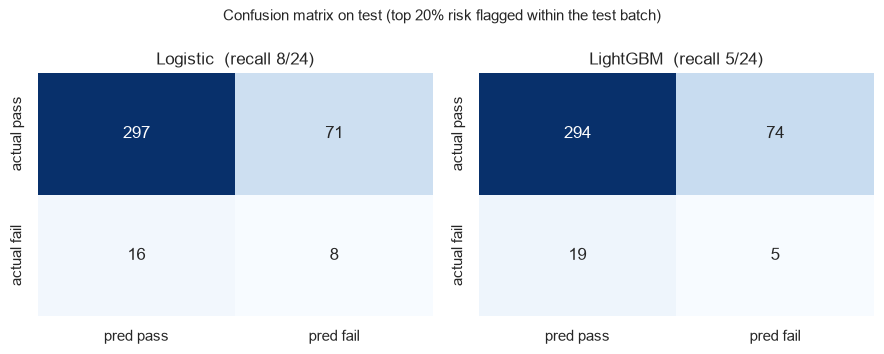

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (name, p) in zip(axes, test_proba.items()):
    pred = (p >= flag_top_rate(p, INSPECT_RATE)).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax,
                xticklabels=["pred pass", "pred fail"], yticklabels=["actual pass", "actual fail"])
    label = "Logistic" if name == "로지스틱 회귀" else "LightGBM"
    ax.set_title(f"{label}  (recall {cm[1,1]}/{cm[1].sum()})")
fig.suptitle("Confusion matrix on test (top 20% risk flagged within the test batch)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_confusion_matrix.png", dpi=150)

**혼동행렬 읽는 법**

| | 모델: 정상 | 모델: 불량 |
|---|---|---|
| **실제 정상** | TN: 맞게 통과 | FP: 괜히 재검사 |
| **실제 불량** | FN: **놓친 불량** | TP: 잡아낸 불량 |

- **재현율** = TP / (TP + FN): 실제 불량 중 잡아낸 비율
- **정밀도** = TP / (TP + FP): 불량이라고 한 것 중 진짜 불량 비율

## 4. 검사 비율을 바꾸면? (누적 이득 곡선)

검사 여력이 20%가 아닐 수도 있으므로, 위험도 순으로 상위 몇 %를 검사했을 때 불량의 몇 %를 잡는지 전 구간을 그린다.
대각선은 무작위로 검사했을 때다. **대각선보다 위에 있을수록** 모델이 위험한 제품을 앞쪽에 잘 모아준다는 뜻이다.

,로지스틱 회귀,LightGBM,무작위
상위 10% 검사,0.167,0.125,0.1
상위 20% 검사,0.333,0.208,0.2
상위 30% 검사,0.417,0.375,0.3
상위 50% 검사,0.667,0.542,0.5


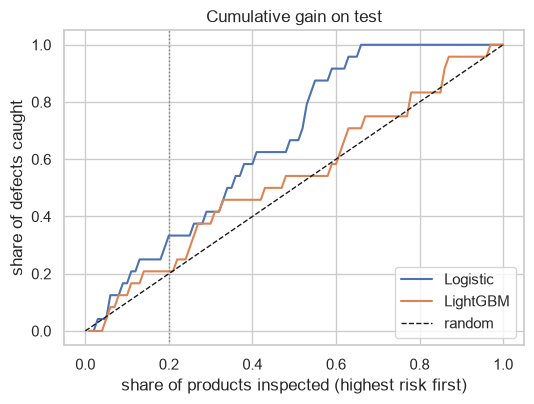

In [5]:
rates = np.linspace(0.01, 1, 100)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for name, p in test_proba.items():
    label = "Logistic" if name == "로지스틱 회귀" else "LightGBM"
    ax.plot(rates, [recall_at_rate(y_test, p, r) for r in rates], label=label)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
ax.axvline(INSPECT_RATE, color="gray", ls=":", lw=1)
ax.set_xlabel("share of products inspected (highest risk first)")
ax.set_ylabel("share of defects caught")
ax.set_title("Cumulative gain on test")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "08_gain_curve.png", dpi=150)

gain = pd.DataFrame({name: [recall_at_rate(y_test, p, r) for r in [0.1, 0.2, 0.3, 0.5]] for name, p in test_proba.items()},
                    index=["상위 10% 검사", "상위 20% 검사", "상위 30% 검사", "상위 50% 검사"])
gain["무작위"] = [0.1, 0.2, 0.3, 0.5]
gain.round(3)

## 5. 이 점수는 믿을 만한가 (부트스트랩 신뢰구간)

test 불량은 24개뿐이다. 불량 한두 개만 달라져도 점수가 크게 바뀐다.
그래서 test를 **복원추출로 2000번 다시 뽑아** 점수가 어느 범위에서 움직이는지 본다.

- 구간의 아래쪽이 **무작위 기준선보다 위**면 "우연이 아니라 실제로 낫다"고 말할 수 있다
- 두 모델 차이의 구간이 **0을 포함**하면 "어느 모델이 낫다고 단정할 수 없다"

In [6]:
base = y_test.mean()
ci_rows = []
for name, p in test_proba.items():
    pr = bootstrap_ci(y_test, p, average_precision_score)
    rc = bootstrap_ci(y_test, p, lambda yt, pp: recall_at_rate(yt, pp, INSPECT_RATE))
    ci_rows.append({"모델": name,
                    "PR-AUC (95% 구간)": f"{pr[0]:.3f} [{pr[1]:.3f}, {pr[2]:.3f}]",
                    "PR-AUC 무작위 기준": f"{base:.3f}",
                    "PR-AUC 구간 하한 > 기준?": pr[1] > base,
                    "상위 20% 검사 재현율 (95% 구간)": f"{rc[0]:.2f} [{rc[1]:.2f}, {rc[2]:.2f}]",
                    "재현율 구간 하한 > 0.20?": rc[1] > INSPECT_RATE})
ci_table = pd.DataFrame(ci_rows).set_index("모델")

names = list(test_proba)
diff = bootstrap_diff_ci(y_test, test_proba[names[0]], test_proba[names[1]])
print(f"PR-AUC 차이 ({names[0]} - {names[1]}): {diff[0]:+.3f}, 95% 구간 [{diff[1]:+.3f}, {diff[2]:+.3f}]")
ci_table.to_csv(REPORT_DIR / "test_confidence_intervals.csv", encoding="utf-8-sig")
ci_table

PR-AUC 차이 (로지스틱 회귀 - LightGBM): +0.023, 95% 구간 [-0.008, +0.071]


,PR-AUC (95% 구간),PR-AUC 무작위 기준,PR-AUC 구간 하한 > 기준?,상위 20% 검사 재현율 (95% 구간),재현율 구간 하한 > 0.20?
모델,,,,,
로지스틱 회귀,"0.097 [0.060, 0.171]",0.061,False,"0.33 [0.14, 0.50]",False
LightGBM,"0.073 [0.044, 0.128]",0.061,False,"0.21 [0.07, 0.40]",False


## 6. 정리

| 질문 | 답 |
|---|---|
| 상위 20%를 검사하면 불량을 몇 개 잡나 | 로지스틱 **8/24 (33%)**, LightGBM 5/24 (21%), 무작위 기대값 약 5/24 (20%) |
| 그 대가는 | 로지스틱 기준 정상품 71개를 함께 재검사 (불량 판정 79개 중 진짜 불량 8개, 정밀도 약 10%) |
| 정확도는 | 0.78. "전부 정상"이라고만 해도 0.94라서 정확도로는 모델을 평가할 수 없다 |
| 무작위보다 확실히 낫나 | **통계적으로 단정할 수 없다.** 두 모델 모두 PR-AUC 95% 구간 하한이 무작위 기준선(0.061) 아래 |
| 로지스틱이 LightGBM보다 낫나 | 점수는 로지스틱이 높지만 차이 구간 [-0.008, +0.071]이 0을 포함한다. 단정할 수 없다 |

**결론**
- 로지스틱 회귀는 모든 검사 비율에서 무작위보다 위에 있다(누적 이득 곡선). 약하지만 일관된 신호가 있다.
  특히 위험도 하위 약 1/3에는 test 불량이 하나도 없었다. 다만 불량 24개 기준이라 확정적인 결론은 아니다.
- LightGBM은 대부분 구간에서 무작위와 비슷하다.
- test 불량이 24개뿐이라 신뢰구간이 넓다. **더 긴 기간의 데이터 없이는 "쓸 만하다"고 말할 수 없다**는 것이 정직한 결론이다.
- 운영 측면에서는 **고정 확률값 대신 할당량(묶음 내 상위 N%) 방식**이 시기 변화에 안정적이라는 것을 확인했다.

다음(05): SHAP으로 모델이 어떤 센서를 보고 판단했는지 확인한다. 성능이 약한 만큼, 해석 결과는 "확정된 원인"이 아니라 **엔지니어가 먼저 점검해 볼 후보**로 다룬다.